In [15]:
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.integrate import odeint

In [16]:
m1 = 1.0
m2 = 1.0
l1 = 1.0
l2 = 1.0
grav = 9.81

In [17]:
t0, tfinal = 0.0, 0.5

In [18]:
def doublePendulum(w, t):
    
    x1, x2, y1, y2 = w
    
    A = l1*l2*(m1 + m2*(jnp.sin(x1 - x2)**2))
    h1 = (y1*y2*jnp.sin(x1 - x2))/A
    h2 = (m2*(l2**2)*(y1**2) + (m1 + m2)*(l1**2)*(y2**2) - 2*m2*l1*l2*y1*y2*jnp.cos(x1 - x2))/(2*A**2)

    x1_t = (l2*y1 - l1*y2*jnp.cos(x1 - x2))/(l1*A)
    x2_t = (-m2*l2*y1*jnp.cos(x1 - x2) + l1*(m1 + m2)*y2)/(m2*l2*A)
    y1_t = -(m1 + m2)*grav*l1*jnp.sin(x1) - h1 + h2*jnp.sin(2*(x1 - x2))
    y2_t = -m2*grav*l2*jnp.sin(x2) + h1 - h2*jnp.sin(2*(x1 - x2))

    dwdt = [x1_t, x2_t, y1_t, y2_t]

    return dwdt

In [19]:
n = 500
t = np.linspace(t0, tfinal, n)

init_data = np.random.uniform(-np.pi/6, np.pi/6, size=(4,))

In [20]:
sol_rk = odeint(doublePendulum, init_data, t)
x1rk, x2rk, y1rk, y2rk = sol_rk[:,0], sol_rk[:,1], sol_rk[:,2], sol_rk[:,3]

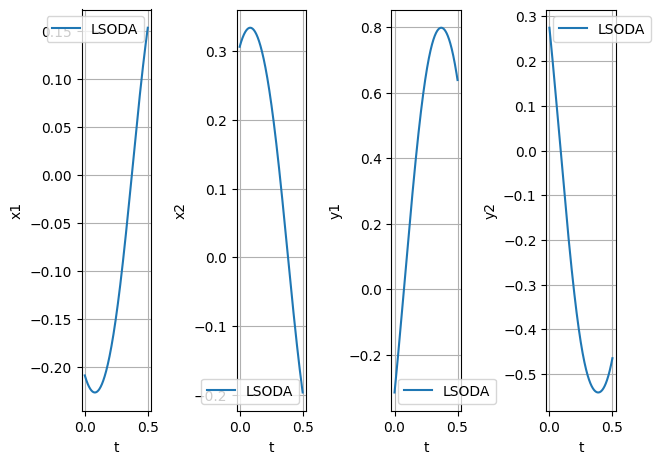

In [21]:
fig = plt.figure()

plt.subplot(1, 4, 1)
plt.tight_layout()
plt.plot(t, x1rk)
plt.xlabel("t")
plt.ylabel("x1")
plt.grid()
plt.legend(['LSODA'])

plt.subplot(1, 4, 2)
plt.tight_layout()
plt.plot(t, x2rk)
plt.xlabel("t")
plt.ylabel("x2")
plt.grid()
plt.legend(['LSODA'])

plt.subplot(1, 4, 3)
plt.tight_layout()
plt.plot(t, y1rk)
plt.xlabel("t")
plt.ylabel("y1")
plt.grid()
plt.legend(['LSODA'])

plt.subplot(1, 4, 4)
plt.tight_layout()
plt.plot(t, y2rk)
plt.xlabel("t")
plt.ylabel("y2")
plt.grid()
plt.legend(['LSODA'])

plt.show()